# Toy Experiments

We want to perform ASR with Continuous Flow Matching. This is, predicting a sequence of categorical tokens by cross-attending to a continuous latent embedding that contains information about the whole sequence.

To do this, we want to consider the following toy experiment. Let's create a vocabulary of $|\mathcal{V}|$ tokens and try to predict sequences of L tokens.

Let's say valid sequences are the ones in which the $\sum_\ell w^\ell = 0$.

We want to condition on $a^\ell = e_{w^\ell} + \eta \, \varepsilon^\ell, \varepsilon \sim \mathcal{N}(0, I)$ with $\eta$ controlling the noise level.

In [40]:
import math
from dataclasses import dataclass
from typing import Optional, Callable
from functools import partial

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchmetrics import Metric

import matplotlib.pyplot as plt

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


### Define HPs

In [2]:
VOCAB_SIZE = 15
SEQ_LENGTH = 8
NUM_SAMPLES = 10000
NUM_VALID_TRANSITIONS = 4
REQUIRE_EVEN_SUM = True

### Create Dataset

In [3]:
def create_transition_matrix(vocab_size, num_valid_transitions, device):
    # row indices: each row repeated k times -> shape (V, k)
    row_idx = torch.arange(vocab_size, device=device).unsqueeze(1).expand(-1, num_valid_transitions)

    # distinct successors per row, sampled without replacement
    col_idx = torch.stack([
        torch.randperm(vocab_size)[:num_valid_transitions]
        for _ in range(vocab_size)
    ])

    transition_matrix = torch.zeros((vocab_size, vocab_size), dtype=torch.int32, device=device)
    transition_matrix[row_idx, col_idx] = 1

    # each row has exactly k successors
    assert (transition_matrix.sum(dim=1) == num_valid_transitions).all()

    return transition_matrix

def count_valid(trans_matrix, seq_length):
    ones = torch.ones(trans_matrix.shape[0], device=trans_matrix.device)
    M = torch.linalg.matrix_power(trans_matrix, seq_length - 1)
    return int((ones @ M @ ones).item())


def sample_sequence(
    trans_matrix,
    sample_size,
    seq_length,
    device=None,
    require_even_sum=True
):
    device = device or trans_matrix.device
    vocab_size = trans_matrix.shape[0]

    # Uniform distribution
    first_token_dist = torch.ones(vocab_size, device=device) / vocab_size

    # Sample first token
    w = torch.zeros(sample_size, seq_length, dtype=torch.long, device=device)
    w[:, 0] = torch.multinomial(first_token_dist, sample_size, replacement=True)

    # Fill the rest of the sequence
    for l in range(1, seq_length):
        probs = trans_matrix[w[:, l - 1]]
        w[:, l] = torch.multinomial(probs, 1).squeeze(1)

    if require_even_sum:
        even_sum_mask = (w.sum(dim=1) % 2 == 0)
        w = w[even_sum_mask]

    return w


In [4]:
transition_matrix = create_transition_matrix(VOCAB_SIZE, NUM_VALID_TRANSITIONS, device=device)
valid_seq_count = count_valid(transition_matrix.float(), seq_length=SEQ_LENGTH)

print(
    f"Valid sequences of length {SEQ_LENGTH}: {valid_seq_count}"
)

# row-normalize for sampling
prob_trans_matrix = transition_matrix.float() / transition_matrix.sum(dim=1, keepdim=True)

all_sequences = torch.empty(0, SEQ_LENGTH, dtype=torch.long, device=device)

if REQUIRE_EVEN_SUM:
    print("Sampling only sequences with even sum.")
    valid_seq_count = int(valid_seq_count * 0.49)  # Adjust this as needed

while all_sequences.shape[0] < valid_seq_count:
    new_samples = sample_sequence(
        prob_trans_matrix, NUM_SAMPLES, SEQ_LENGTH, device=device, require_even_sum=REQUIRE_EVEN_SUM
    )
    all_sequences = torch.cat([all_sequences, new_samples], dim=0)
    all_sequences = torch.unique(all_sequences, dim=0)

print(f"Sampled {all_sequences.shape[0]} unique sequences of length {SEQ_LENGTH} out of {valid_seq_count}.")


Valid sequences of length 8: 245760
Sampling only sequences with even sum.
Sampled 120480 unique sequences of length 8 out of 120422.


### Visualize how corruption messes w predictions

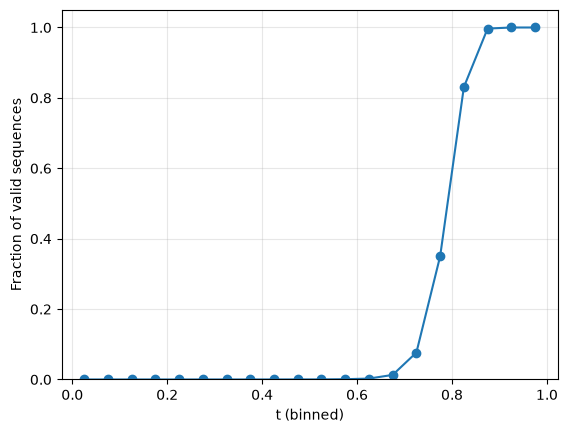

In [5]:
class BinnedValidityMetric(Metric):
    """Tracks fraction of valid sequences (transition legality + optional even-sum
    parity) as a function of the flow time t, aggregated into equal-width bins."""

    def __init__(self, transition_matrix, num_bins=10, require_even_sum=True, **kwargs):
        super().__init__(**kwargs)
        self.register_buffer("transition_matrix", transition_matrix)
        self.num_bins = num_bins
        self.require_even_sum = require_even_sum

        # per-bin running counts; dist_reduce_fx="sum" makes this DDP-safe
        self.add_state("valid_count", default=torch.zeros(num_bins), dist_reduce_fx="sum")
        self.add_state("total_count", default=torch.zeros(num_bins), dist_reduce_fx="sum")

    def _bin_indices(self, t):
        # t in [0, 1] -> bin index in [0, num_bins - 1]
        idx = (t * self.num_bins).long()
        return idx.clamp(max=self.num_bins - 1, min=0)

    def update(self, sequences, t):
        """
        sequences: (B, L) predicted/decoded token ids
        t: (B,) the flow time each sequence was produced/observed at
        """
        prev = sequences[:, :-1]
        nxt = sequences[:, 1:]
        legal = self.transition_matrix[prev, nxt].bool()
        per_sequence_valid = legal.all(dim=1)

        if self.require_even_sum:
            parity_valid = (sequences.sum(dim=1) % 2 == 0)
            per_sequence_valid = per_sequence_valid & parity_valid

        bin_idx = self._bin_indices(t)

        # scatter-add per-sequence validity and counts into their time bins
        self.valid_count.scatter_add_(
            0, bin_idx, per_sequence_valid.float()
        )
        self.total_count.scatter_add_(
            0, bin_idx, torch.ones_like(per_sequence_valid, dtype=torch.float)
        )

    def compute(self):
        # avoid div-by-zero for bins that received no samples
        frac_valid = self.valid_count / self.total_count.clamp(min=1)
        return frac_valid   # (num_bins,) — NaN-free; empty bins report 0.0

    def bin_edges(self):
        return torch.linspace(0, 1, self.num_bins + 1)

    def overall_validity(self) -> float:
        """Aggregate validity across all t-bins into a single scalar,
        weighted by how many samples actually landed in each bin."""
        total = self.total_count.sum()
        if total == 0:
            return float("nan")
        valid = self.valid_count.sum()
        return (valid / total).item()

    def validity_extremes(self, low_frac=0.2, high_frac=0.8):
        binned = self.compute()
        n = binned.shape[0]
        low_bins = binned[: max(1, int(n * low_frac))]
        high_bins = binned[int(n * high_frac):]
        return low_bins.mean().item(), high_bins.mean().item()


def linear_interpolant_simulation(sequences, vocab_size, t):
    onehot = F.one_hot(sequences, num_classes=vocab_size).float()
    noisy = t * onehot + (1 - t) * torch.randn_like(onehot)
    return noisy.argmax(dim=-1)


metric = BinnedValidityMetric(transition_matrix, num_bins=20, require_even_sum=True)
metric = metric.to(device)

for t_val in torch.linspace(0.0, 1.0, 21, device=device):
    t_batch = t_val.expand(all_sequences.size(0))
    noisy_samples = linear_interpolant_simulation(all_sequences, vocab_size=transition_matrix.shape[0], t=t_val.item())
    metric.update(noisy_samples, t_batch)

frac_valid_per_bin = metric.compute()
bin_edges = metric.bin_edges()
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

plt.plot(bin_centers.cpu().numpy(), frac_valid_per_bin.cpu().numpy(), marker="o")
plt.xlabel("t (binned)")
plt.ylabel("Fraction of valid sequences")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.show()

### Design Audio Proxy

In [6]:
def make_phi(
    vocab_size,
    embed_dim,
    num_confusable_pairs=1,
    confusion_noise=0.1,
    device=None,
    generator=None
):
    assert 2 * num_confusable_pairs <= vocab_size, (
        f"Can't form {num_confusable_pairs} disjoint"
        f"pairs from a vocab of size {vocab_size}"
    )

    Phi = torch.randn(
        vocab_size, embed_dim, device=device, generator=generator
    )

    # sample num_confusable_pairs disjoint pairs from V tokens
    perm = torch.randperm(
        vocab_size, generator=generator
    )[: 2 * num_confusable_pairs]
    pairs = perm.view(num_confusable_pairs, 2)  # (num_pairs, 2), each row a disjoint pair

    for i, j in pairs:
        Phi[j] = Phi[i] + confusion_noise * torch.randn(embed_dim, device=device, generator=generator)

    return Phi, pairs

def make_audio_proxy(w, Phi, kernel, eta, audio_dim):
    emb = Phi[w] # (B, L, d)
    emb_t = emb.transpose(1, 2) # (B, d, L)
    smoothed = F.conv1d(
        emb_t,
        kernel.expand(audio_dim, 1, -1),
        padding=kernel.shape[-1]//2,
        groups=audio_dim
    )
    smoothed = smoothed.transpose(1, 2) # (B, L, d)
    return smoothed + eta * torch.randn_like(smoothed, device=smoothed.device)


### Viz Audio Embeddings

In [7]:
def plot_phi_confusability(Phi, pairs, vocab_size):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    # (a) pairwise distance matrix
    dists = torch.cdist(Phi, Phi)
    im = axes[0].imshow(dists.cpu(), cmap="viridis")
    axes[0].set_title("Pairwise distance in Φ-space")
    axes[0].set_xlabel("token")
    axes[0].set_ylabel("token")
    fig.colorbar(im, ax=axes[0], fraction=0.046)

    for i, j in pairs:
        axes[0].scatter([j.item()], [i.item()], marker="x", color="red", s=60)
        axes[0].scatter([i.item()], [j.item()], marker="x", color="red", s=60)

    # (b) 2D projection (PCA) of Phi, only confusable-pair tokens labelled
    Phi_c = Phi - Phi.mean(dim=0, keepdim=True)
    U, S, V = torch.pca_lowrank(Phi_c, q=2)
    proj = Phi_c @ V[:, :2]

    axes[1].scatter(proj[:, 0].cpu(), proj[:, 1].cpu(), s=80, color="tab:blue")

    confusable_tokens = pairs.reshape(-1)  # flatten (num_pairs, 2) -> all involved token indices
    for v in confusable_tokens:
        v = v.item()
        axes[1].annotate(str(v), (proj[v, 0].item(), proj[v, 1].item()), fontsize=12, fontweight="bold",
                          xytext=(4, 4), textcoords="offset points")

    for i, j in pairs:
        axes[1].plot([proj[i, 0].item(), proj[j, 0].item()],
                      [proj[i, 1].item(), proj[j, 1].item()], "r--", alpha=0.7)
    axes[1].set_title("Φ projected to 2D (PCA), confusable pairs linked")

    fig.tight_layout()
    plt.show()


def plot_audio_proxy_confusion(Phi, kernel, audio_dim, w, eta_values):
    """For one fixed batch of ground-truth sequences w, sweep eta and measure
    how often nearest-neighbour decoding of the audio proxy recovers the
    original token, split into 'involves a confusable token' vs not."""

    frac_correct = []

    for eta in eta_values:
        a = make_audio_proxy(w, Phi, kernel, eta, audio_dim)   # (B, L, d)
        # nearest-neighbour decode: which token's Phi row is closest to each a^l
        dists = torch.cdist(a.reshape(-1, audio_dim), Phi)      # (B*L, V)
        pred = dists.argmin(dim=1).reshape(w.shape)              # (B, L)

        correct = (pred == w)
        frac_correct.append(correct.float().mean().item())

    plt.figure(figsize=(6, 4))
    plt.plot(eta_values, frac_correct, marker="o")
    plt.xlabel("eta (noise scale)")
    plt.ylabel("Nearest-neighbour decode accuracy")
    plt.title("Audio proxy informativeness vs eta")
    plt.ylim(0, 1.05)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Define Models

In [8]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):  # t: (B,)
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = t[:, None] * freqs[None, :]  # (B, half)
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)  # (B, dim)


class DenoiserBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        # bidirectional self-attention — no causal mask, the model sees all positions
        h = self.norm1(x)
        x = x + self.attn(h, h, h, need_weights=False)[0]
        x = x + self.ff(self.norm2(x))
        return x

class Denoiser(nn.Module):
    def __init__(self, vocab_size, seq_len, audio_dim=None, d_model=128, n_heads=4, n_layers=3, d_ff=256):
        super().__init__()
        audio_dim = audio_dim if audio_dim is not None else vocab_size  # default: plain one-hot proxy
        self.x_proj = nn.Linear(vocab_size, d_model)
        self.a_proj = nn.Linear(audio_dim, d_model)
        self.time_embed = SinusoidalTimeEmbedding(d_model)
        self.pos_embed = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        self.blocks = nn.ModuleList([DenoiserBlock(d_model, n_heads, d_ff) for _ in range(n_layers)])
        self.norm_out = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x_t, t, a):
        # x_t: (B, L, V), t: (B,), a: (B, L, audio_dim)
        h = self.x_proj(x_t) + self.a_proj(a) + self.pos_embed
        h = h + self.time_embed(t)[:, None, :]
        for block in self.blocks:
            h = block(h)
        return self.head(self.norm_out(h))

class AudioDecoder(nn.Module):
    """r_psi: predicts per-token categorical distributions from audio alone.
    Strictly factorized across positions — no attention, no dependence on x_t or t.
    """
    def __init__(self, audio_dim, vocab_size, hidden_dim=128, n_layers=2):
        super().__init__()
        layers = []
        in_dim = audio_dim
        for _ in range(n_layers - 1):
            layers += [nn.Linear(in_dim, hidden_dim), nn.GELU()]
            in_dim = hidden_dim
        layers.append(nn.Linear(in_dim, vocab_size))
        self.net = nn.Sequential(*layers)

    def forward(self, a):
        return self.net(a)

### Define Interpolation Function

In [9]:
def make_interpolant(x1, t, alpha_fn, beta_fn, gamma_fn=None, mu=None, stop_grad_mu=False, device=None):
    device = device if device is not None else x1.device
    x0 = torch.randn_like(x1, device=device)
    I_t = alpha_fn(t)[:, None, None] * x0 + beta_fn(t)[:, None, None] * x1
    if gamma_fn is not None and mu is not None:
        mu_term = mu.detach() if stop_grad_mu else mu
        I_t = I_t + gamma_fn(t)[:, None, None] * mu_term
    return I_t

### Auxiliary Fns

In [38]:
def format_epoch_log(epoch, config, train_metrics, val_metrics,
                      train_validity_metric, val_validity_metric):
    lines = []
    lines.append(f"{'='*60}")
    lines.append(f"Epoch {epoch+1:>4}/{config.num_epochs}")
    lines.append(f"{'-'*60}")

    has_mu = train_metrics.get("mu_loss", 0.0) > 0.0

    if has_mu:
        lines.append(
            f"{'':12}{'denoiser':>10}{'mu':>10}{'total':>10}"
        )
        lines.append(
            f"{'train':12}{train_metrics['denoiser_loss']:>10.4f}"
            f"{train_metrics['mu_loss']:>10.4f}{train_metrics['loss']:>10.4f}"
        )
        lines.append(
            f"{'val':12}{val_metrics['denoiser_loss']:>10.4f}"
            f"{val_metrics['mu_loss']:>10.4f}{val_metrics['loss']:>10.4f}"
        )
    else:
        lines.append(f"{'':12}{'loss':>10}")
        lines.append(f"{'train':12}{train_metrics['loss']:>10.4f}")
        lines.append(f"{'val':12}{val_metrics['loss']:>10.4f}")

    train_overall = train_validity_metric.overall_validity()
    val_overall = val_validity_metric.overall_validity()
    train_low, train_high = train_validity_metric.validity_extremes()
    val_low, val_high = val_validity_metric.validity_extremes()

    lines.append(f"{'-'*60}")
    lines.append(f"{'':12}{'valid%':>10}{'low-t':>10}{'high-t':>10}")
    lines.append(f"{'train':12}{train_overall*100:>9.1f}%{train_low*100:>9.1f}%{train_high*100:>9.1f}%")
    lines.append(f"{'val':12}{val_overall*100:>9.1f}%{val_low*100:>9.1f}%{val_high*100:>9.1f}%")

    return "\n".join(lines)


def format_binned_validity(train_metrics, val_metrics, validity_metric):
    bin_edges = validity_metric.bin_edges()
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    train_binned = train_metrics.get("binned_validity")
    val_binned = val_metrics.get("binned_validity")

    lines = [f"{'-'*60}", "t-binned valid%"]
    header = "  t:    " + " ".join(f"{c:5.2f}" for c in bin_centers.tolist())
    train_row = "  train:" + " ".join(f"{v*100:5.1f}" for v in train_binned.tolist())
    val_row = "  val:  " + " ".join(f"{v*100:5.1f}" for v in val_binned.tolist())
    lines += [header, train_row, val_row]
    return "\n".join(lines)

In [45]:
def plot_losses(history):
    has_mu = "mu_loss" in history["train"][0] and history["train"][0]["mu_loss"] > 0.0

    epochs = np.arange(1, len(history["train"]) + 1)
    train_loss = [m["loss"] for m in history["train"]]
    val_loss = [m["loss"] for m in history["val"]]

    n_panels = 3 if has_mu else 1
    fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 4), squeeze=False)
    axes = axes[0]

    axes[0].plot(epochs, train_loss, label="train", color="tab:blue")
    axes[0].plot(epochs, val_loss, label="val", color="tab:orange")
    axes[0].set_title("Total loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    if has_mu:
        denoiser_train = [m["denoiser_loss"] for m in history["train"]]
        denoiser_val = [m["denoiser_loss"] for m in history["val"]]
        mu_train = [m["mu_loss"] for m in history["train"]]
        mu_val = [m["mu_loss"] for m in history["val"]]

        axes[1].plot(epochs, denoiser_train, label="train", color="tab:blue")
        axes[1].plot(epochs, denoiser_val, label="val", color="tab:orange")
        axes[1].set_title("Denoiser loss")
        axes[1].set_xlabel("epoch")
        axes[1].legend()
        axes[1].grid(alpha=0.3)

        axes[2].plot(epochs, mu_train, label="train", color="tab:blue")
        axes[2].plot(epochs, mu_val, label="val", color="tab:orange")
        axes[2].set_title("μ (audio decoder) loss")
        axes[2].set_xlabel("epoch")
        axes[2].legend()
        axes[2].grid(alpha=0.3)

    fig.tight_layout()
    plt.show()


def plot_validity_evolution(history, validity_metric, split="train"):
    """
    history: your history dict, where history[split][e]['binned_validity'] is a
             (num_bins,) tensor for epoch e (only present on logged epochs).
    validity_metric: any BinnedValidityMetric instance, used only for its bin_edges().
    """
    bin_edges = validity_metric.bin_edges().cpu().numpy()
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # collect only the epochs where binned_validity was actually logged
    logged = [(e, m["binned_validity"]) for e, m in enumerate(history[split])
              if m.get("binned_validity") is not None]
    if not logged:
        raise ValueError(f"No binned_validity entries found in history['{split}']")

    epoch_idxs, binned = zip(*logged)
    matrix = np.stack([b.cpu().numpy() if hasattr(b, "numpy") else np.asarray(b) for b in binned])
    # matrix shape: (num_logged_epochs, num_bins)

    fig, ax = plt.subplots(figsize=(8, 5))
    im = ax.imshow(
        matrix.T,                     # bins on y-axis, epoch on x-axis
        aspect="auto",
        origin="lower",
        cmap="magma",
        vmin=0, vmax=1,
        extent=[epoch_idxs[0], epoch_idxs[-1], bin_edges[0], bin_edges[-1]],
    )
    ax.set_xlabel("epoch")
    ax.set_ylabel("t")
    ax.set_title(f"Validity fraction across t-bins over training ({split})")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("fraction valid")

    fig.tight_layout()
    plt.show()


def plot_validity_ridgeline(history, validity_metric, split="train", n_curves=8):
    bin_edges = validity_metric.bin_edges().cpu().numpy()
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    logged = [(e, m["binned_validity"]) for e, m in enumerate(history[split])
              if m.get("binned_validity") is not None]
    if not logged:
        raise ValueError(f"No binned_validity entries found in history['{split}']")

    stride = max(1, len(logged) // n_curves)
    selected = logged[::stride]

    fig, ax = plt.subplots(figsize=(7, 5))
    cmap = plt.cm.viridis
    for i, (epoch, binned) in enumerate(selected):
        color = cmap(i / max(1, len(selected) - 1))
        vals = binned.cpu().numpy() if hasattr(binned, "numpy") else np.asarray(binned)
        ax.plot(bin_centers, vals, color=color, label=f"epoch {epoch+1}", alpha=0.85)

    ax.set_xlabel("t")
    ax.set_ylabel("fraction valid")
    ax.set_ylim(0, 1.05)
    ax.set_title(f"Validity vs t across training ({split})")
    ax.legend(fontsize=8, loc="upper left", ncol=2)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

### Define Training Loop

In [52]:

def make_epoch_loader(sequences, batch_size, shuffle):
    return torch.utils.data.DataLoader(sequences, batch_size=batch_size, shuffle=shuffle)

def run_epoch(
    model,
    loader,
    device,
    interpolant_fn,
    optimizer=None,
    scheduler=None,
    audio_sigma=0.5,
    audio_proxy_fn=None,
    mu_nn=None,
    mu_loss_weight=1.0,
    validity_metric: Optional[Metric] = None
):
    """One pass over `loader`. If optimizer is given, trains; otherwise evaluates.
    Returns a dict of epoch-averaged metrics."""
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()

    total_denoiser_loss, total_mu_loss = 0.0, 0.0
    total_loss, total_seqs = 0.0, 0
    total_valid, total_unique_valid = 0, 0

    ctx = torch.enable_grad() if train_mode else torch.no_grad()
    with ctx:
        for batch in loader:
            batch = batch.to(device)
            B = batch.size(0)
            vocab_size = model.head.out_features

            x1 = F.one_hot(batch, vocab_size).float()

            if audio_proxy_fn is not None:
                a = audio_proxy_fn(batch)
            else:
                a = x1 + audio_sigma * torch.randn_like(x1)

            if mu_nn is not None:
                mu_logits = mu_nn(a)
                mu = F.softmax(mu_logits, dim=-1)
            else:
                mu = None

            t = torch.rand(B, device=device)
            I_t = interpolant_fn(x1=x1, t=t, mu=mu, device=device)

            logits = model(I_t, t, a)
            denoiser_loss = F.cross_entropy(logits.reshape(-1, vocab_size), batch.reshape(-1))

            total_denoiser_loss += denoiser_loss.item() * B

            if mu_nn is not None:
                mu_loss = F.cross_entropy(mu_logits.reshape(-1, vocab_size), batch.reshape(-1))
                total_mu_loss += mu_loss.item() * B
                loss = denoiser_loss + mu_loss_weight * mu_loss
            else:
                loss = denoiser_loss

            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()

            pred_sequences = logits.argmax(dim=-1)
            if validity_metric is not None:
                validity_metric.update(pred_sequences, t)

            total_loss += loss.item() * B
            total_seqs += B

    binned_validity = None
    if validity_metric is not None:
        binned_validity = validity_metric.compute()

    return {
        "loss": total_loss / total_seqs,
        "denoiser_loss": total_denoiser_loss / total_seqs,
        "mu_loss": total_mu_loss / total_seqs,
        "binned_validity": binned_validity,
    }


@dataclass
class TrainConfig:
    num_epochs: int = 1000
    audio_sigma: float = 0.5
    require_even_sum: bool = True
    mu_loss_weight: float = 1.0
    log_every: int = 1
    audio_proxy_fn: Optional[Callable] = None
    interpolant_fn: Callable = None  # required — no sensible default

    def __post_init__(self):
        if self.interpolant_fn is None:
            raise ValueError("interpolant_fn must be provided")


def train(
    model,
    loader_train,
    loader_val,
    device,
    optimizer,
    scheduler,
    metrics,
    config: TrainConfig,
    mu_nn=None,
):
    history = {"train": [], "val": []}
    train_validity_metric = metrics.get("train")
    val_validity_metric = metrics.get("val")

    for epoch in range(config.num_epochs):
        # Reset the metrics
        train_validity_metric.reset()
        val_validity_metric.reset()

        train_metrics = run_epoch(
            model,
            loader_train,
            device,
            interpolant_fn=config.interpolant_fn,
            optimizer=optimizer,
            scheduler=scheduler,
            audio_sigma=config.audio_sigma,
            audio_proxy_fn=config.audio_proxy_fn,
            mu_nn=mu_nn,
            mu_loss_weight=config.mu_loss_weight,
            validity_metric=train_validity_metric
        )
        val_metrics = run_epoch(
            model,
            loader_val,
            device,
            interpolant_fn=config.interpolant_fn,
            optimizer=None,
            scheduler=None,
            audio_sigma=config.audio_sigma,
            audio_proxy_fn=config.audio_proxy_fn,
            mu_nn=mu_nn,
            mu_loss_weight=config.mu_loss_weight,
            validity_metric=val_validity_metric
        )

        history["train"].append(train_metrics)
        history["val"].append(val_metrics)

        if epoch % config.log_every == 0:
            print(format_epoch_log(epoch, config, train_metrics, val_metrics,
                                    train_validity_metric, val_validity_metric))

        if epoch % (config.log_every * 10) == 0:
            print(format_binned_validity(train_metrics, val_metrics, train_validity_metric))
        print()

    return history

### Shuffle and Split Datasets

In [11]:
BS = 2048

perm = torch.randperm(all_sequences.size(0))
all_sequences = all_sequences[perm]

train_size = int(0.8 * all_sequences.size(0))
train_data = all_sequences[:train_size]
val_data = all_sequences[train_size:]

train_loader = make_epoch_loader(train_data, BS, shuffle=True)
val_loader = make_epoch_loader(val_data, BS, shuffle=False)


### Make Audio Proxy

confusable pairs: tensor([[ 5,  8],
        [13,  4]])


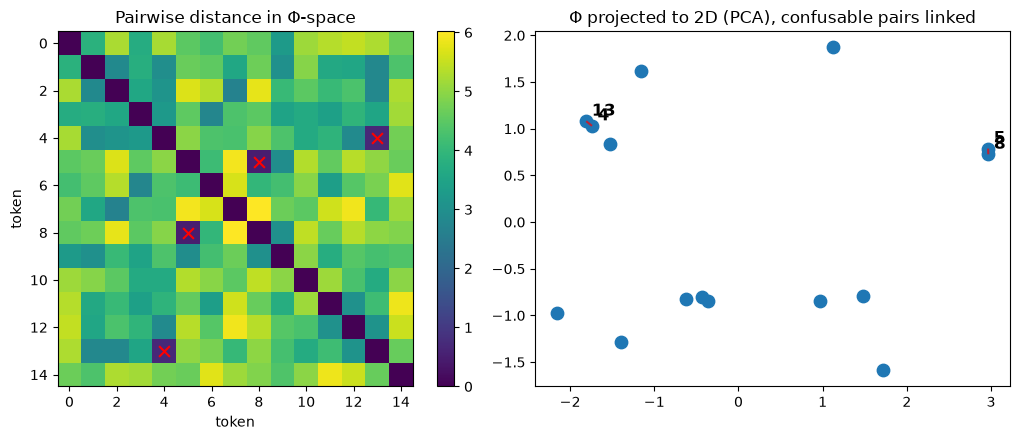

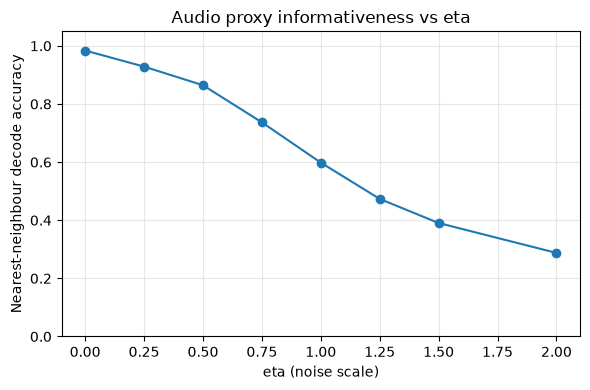

In [12]:
AUDIO_DIM = 10
CONFUSION_NOISE = 0.2
NUM_CONFUSABLE_PAIRS = 2
ETA = 1
KERNEL = torch.tensor([0.1, 0.8, 0.1], device=device).view(1, 1, 3)

Phi, confusable_pairs = make_phi(
    VOCAB_SIZE,
    AUDIO_DIM,
    num_confusable_pairs=NUM_CONFUSABLE_PAIRS,
    confusion_noise=CONFUSION_NOISE,
    device=device
)
print("confusable pairs:", confusable_pairs)
plot_phi_confusability(Phi, confusable_pairs, vocab_size=8)

audio_proxy_fn = partial(
    make_audio_proxy, Phi=Phi, kernel=KERNEL, eta=ETA, audio_dim=AUDIO_DIM
)

eta_values = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
plot_audio_proxy_confusion(Phi, KERNEL, audio_dim=AUDIO_DIM, w=all_sequences[:2048], eta_values=eta_values)


### Train Regular Flow

Epoch    1/50
------------------------------------------------------------
                  loss
train           1.5142
val             0.9770
------------------------------------------------------------
                valid%     low-t    high-t
train             3.5%      1.5%      6.2%
val               8.0%      2.0%     16.5%
------------------------------------------------------------
t-binned valid%
  t:     0.05  0.15  0.25  0.35  0.45  0.55  0.65  0.75  0.85  0.95
  train:  1.3   1.7   2.2   2.3   3.0   3.5   3.8   4.7   5.7   6.8
  val:    1.8   2.2   3.8   4.4   6.4   7.4   9.5  12.2  15.2  17.9

Epoch    2/50
------------------------------------------------------------
                  loss
train           0.8922
val             0.8446
------------------------------------------------------------
                valid%     low-t    high-t
train            12.4%      1.8%     29.0%
val              15.2%      1.6%     39.7%

Epoch    3/50
-----------------------------------

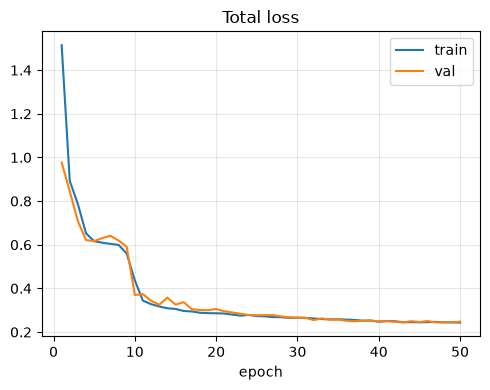

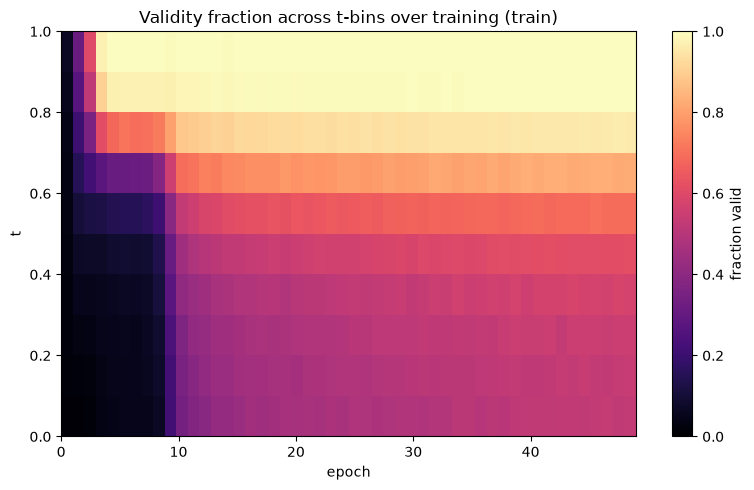

In [47]:

NUM_EPOCHS = 50
AUDIO_SIGMA = 0.5
MAX_LR = 1e-2

# Define the Model
model = Denoiser(vocab_size=VOCAB_SIZE, seq_len=SEQ_LENGTH, audio_dim=AUDIO_DIM).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR)

steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=MAX_LR,
    total_steps=steps_per_epoch * NUM_EPOCHS,
)

# Define Linear Interpolant Function
interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
)

# Define Metrics
train_validity_metric = BinnedValidityMetric(transition_matrix, require_even_sum=REQUIRE_EVEN_SUM)
train_validity_metric = train_validity_metric.to(device)
val_validity_metric = BinnedValidityMetric(transition_matrix, require_even_sum=REQUIRE_EVEN_SUM)
val_validity_metric = val_validity_metric.to(device)
metrics = {
    "train": train_validity_metric,
    "val": val_validity_metric,
}

config = TrainConfig(
    num_epochs=NUM_EPOCHS,
    audio_sigma=AUDIO_SIGMA,
    require_even_sum=REQUIRE_EVEN_SUM,
    mu_loss_weight=None,
    audio_proxy_fn=audio_proxy_fn,
    interpolant_fn=interpolant_fn,
)

history = train(
    model=model,
    loader_train=train_loader,
    loader_val=val_loader,
    device=device,
    optimizer=optimizer,
    scheduler=scheduler,
    metrics=metrics,
    config=config,
    mu_nn=None,
)

plot_losses(history)
plot_validity_evolution(history, train_validity_metric, split="train")

### Train Audio-Conditioned Variant

In [ ]:
NUM_EPOCHS = 50
AUDIO_SIGMA = 0.5
DENOISER_LR = 1e-2
AUDIO_DECODER_LR = 5e-2
STOP_GRAD_MU = True

# Define the Model
model = Denoiser(vocab_size=VOCAB_SIZE, seq_len=SEQ_LENGTH, audio_dim=AUDIO_DIM).to(device)
mu_nn = AudioDecoder(audio_dim=AUDIO_DIM, vocab_size=VOCAB_SIZE).to(device)
param_groups = [
    {"params": model.parameters(), "lr": DENOISER_LR},
    {"params": mu_nn.parameters(), "lr": AUDIO_DECODER_LR},
]
optimizer = torch.optim.AdamW(param_groups)

steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=[DENOISER_LR, AUDIO_DECODER_LR],
    total_steps=steps_per_epoch * NUM_EPOCHS,
)

# Define Audio-Conditioned Linear Interpolant Function
interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
    gamma_fn=lambda t: 1 - t,
    stop_grad_mu=STOP_GRAD_MU
)

# Define Metrics
train_validity_metric = BinnedValidityMetric(transition_matrix, require_even_sum=REQUIRE_EVEN_SUM)
train_validity_metric = train_validity_metric.to(device)
val_validity_metric = BinnedValidityMetric(transition_matrix, require_even_sum=REQUIRE_EVEN_SUM)
val_validity_metric = val_validity_metric.to(device)
metrics = {
    "train": train_validity_metric,
    "val": val_validity_metric,
}

config = TrainConfig(
    num_epochs=NUM_EPOCHS,
    audio_sigma=AUDIO_SIGMA,
    require_even_sum=REQUIRE_EVEN_SUM,
    mu_loss_weight=1.0,
    audio_proxy_fn=audio_proxy_fn,
    interpolant_fn=interpolant_fn,
)

history = train(
    model=model,
    loader_train=train_loader,
    loader_val=val_loader,
    device=device,
    optimizer=optimizer,
    scheduler=scheduler,
    metrics=metrics,
    config=config,
    mu_nn=mu_nn,
)

plot_losses(history)
plot_validity_evolution(history, train_validity_metric, split="train")

Epoch    1/50
------------------------------------------------------------
              denoiser        mu     total
train           1.5541    1.8081    3.3622
val             0.9782    1.1817    2.1599
------------------------------------------------------------
                valid%     low-t    high-t
train             3.3%      1.4%      5.8%
val               8.1%      2.7%     16.6%
------------------------------------------------------------
t-binned valid%
  t:     0.05  0.15  0.25  0.35  0.45  0.55  0.65  0.75  0.85  0.95
  train:  1.3   1.5   2.0   2.3   3.1   2.9   3.7   4.6   5.5   6.0
  val:    2.4   3.0   3.3   4.4   6.4   8.2   8.3  12.4  15.5  17.7

Epoch    2/50
------------------------------------------------------------
              denoiser        mu     total
train           0.8851    1.1057    1.9908
val             0.8253    1.0815    1.9068
------------------------------------------------------------
                valid%     low-t    high-t
train           

### Train Three-Term Waypoint Variant

In [ ]:
NUM_EPOCHS = 50
AUDIO_SIGMA = 0.5
DENOISER_LR = 1e-2
AUDIO_DECODER_LR = 5e-2
# Make it peak at 0.5
C = 0.5

# Define the Model
model = Denoiser(vocab_size=VOCAB_SIZE, seq_len=SEQ_LENGTH, audio_dim=AUDIO_DIM).to(device)
mu_nn = AudioDecoder(audio_dim=AUDIO_DIM, vocab_size=VOCAB_SIZE).to(device)
param_groups = [
    {"params": model.parameters(), "lr": DENOISER_LR},
    {"params": mu_nn.parameters(), "lr": AUDIO_DECODER_LR},
]
optimizer = torch.optim.AdamW(param_groups)

steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=[DENOISER_LR, AUDIO_DECODER_LR],
    total_steps=steps_per_epoch * NUM_EPOCHS,
)

# Define Three-term Waypoint Interpolant Function
interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
    gamma_fn=lambda t: 4 * C * t * (1 - t),
)

# Define Metrics
train_validity_metric = BinnedValidityMetric(transition_matrix, require_even_sum=REQUIRE_EVEN_SUM)
train_validity_metric = train_validity_metric.to(device)
val_validity_metric = BinnedValidityMetric(transition_matrix, require_even_sum=REQUIRE_EVEN_SUM)
validity_metric = val_validity_metric.to(device)
metrics = {
    "train": train_validity_metric,
    "val": val_validity_metric,
}

config = TrainConfig(
    num_epochs=NUM_EPOCHS,
    audio_sigma=AUDIO_SIGMA,
    require_even_sum=REQUIRE_EVEN_SUM,
    mu_loss_weight=None,
    audio_proxy_fn=audio_proxy_fn,
    interpolant_fn=interpolant_fn,
)

history = train(
    model=model,
    loader_train=train_loader,
    loader_val=val_loader,
    transition_matrix=transition_matrix,
    device=device,
    optimizer=optimizer,
    scheduler=scheduler,
    metrics=metrics,
    config=config,
    mu_nn=None,
)